# 02: Evaluation walkthrough

**Offline reproduction, not a new experiment.** This notebook reads committed score rows, aggregate metrics and paired comparisons. It recomputes the two-run headline and paired 95% intervals using the seed, iteration order and case-resampling logic in [final_mean.py](../scripts/final_mean.py), without importing that script because it overwrites the frozen aggregate. It never generates, judges, embeds or reranks text and needs no keys or private report corpus.

Read the [evaluation report](../docs/evaluation-report.md) for scoring definitions and provenance. Behaviour accuracy means matching the expected answer status, not full factual correctness. Costs are historical estimates, not new charges or provider invoices. The first and second runs are both retained; the headline averages them. Two runs do not estimate model run-to-run variance reliably.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'data/processed/observations.parquet').is_file())
def load_json(relative):
    return json.loads((ROOT / relative).read_text())


In [2]:
headline = load_json('experiments/eval/final-mean.json')
SETS = {
    'dev': ('agent-dev-FIN-{arm}', 'agent-dev-FIN2-{arm}'),
    'registered': ('agent-heldout-FIN-{arm}', 'agent-heldout-FIN2-{arm}'),
    'fresh': ('agent-heldout-FINV2-{arm}', 'agent-heldout-FIN2V2-{arm}'),
}
MODELS = ['gpt-6-luna', 'gpt-5.6-luna']
def scored_rows(experiment, model):
    path = ROOT / 'experiments/eval' / experiment / f'{model}.cases.jsonl'
    rows = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    indexed = {row['case_id']: row for row in rows}
    assert len(indexed) == len(rows), path
    return indexed

# Preserve the single RNG and loop order used by final_mean.py.
rng = np.random.default_rng(headline['seed'])
recomputed = {}
for split, experiments in SETS.items():
    recomputed[split] = {}
    for model in MODELS:
        per = {}
        for arm in ('r3', 'hybrid'):
            a, b = [scored_rows(exp.format(arm=arm), model) for exp in experiments]
            ids = sorted(set(a) & set(b))
            assert len(ids) == len(a) == len(b)
            o1 = np.array([bool(a[i]['behavior_ok']) for i in ids], float)
            o2 = np.array([bool(b[i]['behavior_ok']) for i in ids], float)
            per[arm] = {
                'run1': float(o1.mean()), 'run2': float(o2.mean()),
                'mean': float((o1.mean() + o2.mean()) / 2),
                'over_abstain': [round(float(np.mean([bool(run[i]['over_abstain']) for i in ids])), 4) for run in (a, b)],
                'false_answer': [round(float(np.mean([bool(run[i]['false_answer']) for i in ids])), 4) for run in (a, b)],
                'cost': [round(float(np.mean([run[i]['cost_usd'] for i in ids])), 5) for run in (a, b)],
                'p50_s': [round(float(np.median([run[i]['seconds'] for i in ids])), 1) for run in (a, b)],
                'case_mean': (o1 + o2) / 2,
                'ids': ids,
            }
        assert per['r3']['ids'] == per['hybrid']['ids']
        d = per['r3']['case_mean'] - per['hybrid']['case_mean']
        n = len(d)
        boots = [d[rng.integers(0, n, n)].mean() for _ in range(headline['n_boot'])]
        d1 = per['r3']['run1'] - per['hybrid']['run1']
        d2 = per['r3']['run2'] - per['hybrid']['run2']
        recomputed[split][model] = {
            'n': n,
            **{arm: {k: v for k, v in per[arm].items() if k not in ('ids', 'case_mean')} for arm in per},
            'paired_mean_diff': round(float(d.mean()), 4),
            'ci95': [round(float(np.percentile(boots, q)), 4) for q in (2.5, 97.5)],
            'run1_diff': round(d1, 4), 'run2_diff': round(d2, 4),
            'sign_agrees': bool(d1 * d2 > 0 or (d1 == 0 and d2 == 0)),
        }
assert recomputed == headline['sets'], 'Committed headline differs from its saved case rows'
print('All six split/model headline records match, including intervals, cost and latency.')


All six split/model headline records match, including intervals, cost and latency.


,set,model,n,r3 run1,r3 run2,r3 mean,hybrid run1,hybrid run2,hybrid mean,difference,95% interval
0,dev,gpt-6-luna,237,0.8861,0.9072,0.8966,0.8439,0.8101,0.8270,0.0696,"[0.0359, 0.1055]"
1,dev,gpt-5.6-luna,237,0.8987,0.8945,0.8966,0.8397,0.8481,0.8439,0.0527,"[0.019, 0.0886]"
2,registered,gpt-6-luna,31,0.8387,0.8387,0.8387,0.8387,0.7742,0.8065,0.0323,"[-0.0323, 0.1129]"
3,registered,gpt-5.6-luna,31,0.8387,0.8387,0.8387,0.8387,0.8065,0.8226,0.0161,"[-0.0806, 0.129]"
4,fresh,gpt-6-luna,65,0.7077,0.7231,0.7154,0.7538,0.7385,0.7462,-0.0308,"[-0.0769, 0.0077]"
5,fresh,gpt-5.6-luna,65,0.7231,0.7385,0.7308,0.7231,0.7538,0.7385,-0.0077,"[-0.0231, 0.0]"


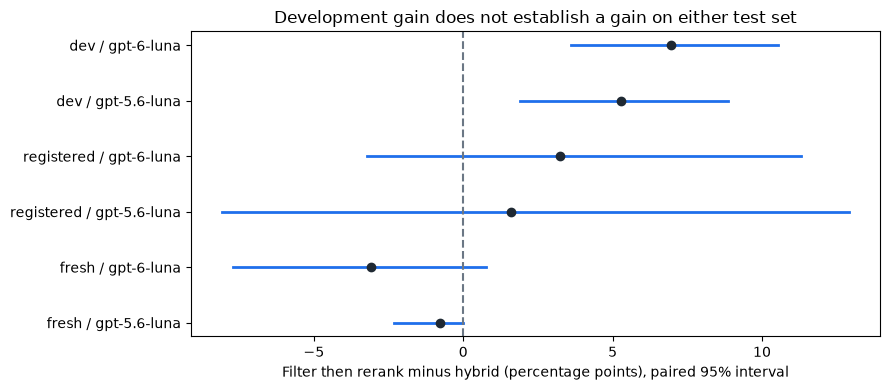

In [3]:
headline_rows = []
for split, models in recomputed.items():
    for model, result in models.items():
        headline_rows.append({
            'set': split, 'model': model, 'n': result['n'],
            'r3 run1': result['r3']['run1'], 'r3 run2': result['r3']['run2'],
            'r3 mean': result['r3']['mean'], 'hybrid run1': result['hybrid']['run1'],
            'hybrid run2': result['hybrid']['run2'], 'hybrid mean': result['hybrid']['mean'],
            'difference': result['paired_mean_diff'], '95% interval': result['ci95'],
        })
headline_table = pd.DataFrame(headline_rows)
display(headline_table.round(4))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
for y, row in headline_table.iterrows():
    low, high = row['95% interval']
    ax.plot([100 * low, 100 * high], [y, y], color='#1f6feb', linewidth=2)
    ax.plot(100 * row['difference'], y, 'o', color='#1f2933')
ax.set_yticks(range(len(headline_table)), headline_table['set'] + ' / ' + headline_table['model'])
ax.axvline(0, color='#6b7785', linestyle='--')
ax.set_xlabel('Filter then rerank minus hybrid (percentage points), paired 95% interval')
ax.set_title('Development gain does not establish a gain on either test set')
ax.invert_yaxis()
fig.tight_layout()
display(fig)
plt.close(fig)


## Retrieval: distinguish the current ladder from the method baseline

Both comparisons use the same 128 answerable development text-evidence cases on corpus v3.1 with 1,847 chunks. BM25 is the non-LLM baseline. Dense uses `text-embedding-3-large`; hybrid combines lexical and dense ranks. The ladder then examines period/release filtering, reranking and their combination. These are development-tuned results, not held-out retrieval results. The cells below recompute hit@8 and MRR@10 from recorded ranks; the saved intervals are displayed, not re-estimated here. Hit@8 requires any expected evidence in the first eight chunks, not every necessary passage in the final answer context.


In [4]:
methods = load_json('experiments/runs/dev-R-V31-methods/metrics.json')
ladder = load_json('experiments/runs/dev-R-V31/summary.json')
assert methods['config']['corpus_version'] == 'v3.1'
assert methods['config']['chunk_count'] == 1847
assert methods['config']['corpus_hash'] == ladder['corpus_hash']
method_scores = [json.loads(line) for line in (ROOT / 'experiments/runs/dev-R-V31-methods/scores.jsonl').read_text().splitlines()]
def validate_ranks(rows, rank_key, expected):
    ranks = [row[rank_key] for row in rows]
    assert len(rows) == expected['n_cases'] == 128
    hit = np.mean([rank is not None and 0 < rank <= 8 for rank in ranks])
    mrr = np.mean([1 / rank if rank is not None and 0 < rank <= 10 else 0 for rank in ranks])
    assert round(float(hit), 4) == expected['hit@8']
    assert round(float(mrr), 4) == expected['mrr@10']
retrieval_rows = []
for method, metrics in methods['metrics'].items():
    validate_ranks(method_scores, f'{method}_first_relevant_rank', metrics)
    retrieval_rows.append({'comparison': 'methods', 'method': method, **{k: metrics[k] for k in ('hit@8', 'hit@8_ci95', 'mrr@10')}})
for arm, label in [('R0', 'hybrid'), ('R1a', 'filter only'), ('R2', 'rerank only'), ('R3', 'filter then rerank')]:
    scores = [json.loads(line) for line in (ROOT / f'experiments/runs/dev-R-V31-{arm}/scores.jsonl').read_text().splitlines()]
    metrics = ladder['metrics'][arm]
    validate_ranks(scores, 'first_relevant_rank', metrics)
    assert {row['case_id'] for row in scores} == {row['case_id'] for row in method_scores}
    retrieval_rows.append({'comparison': 'ladder', 'method': label, **{k: metrics[k] for k in ('hit@8', 'hit@8_ci95', 'mrr@10')}})
assert methods['metrics']['hybrid']['hit@8'] == ladder['metrics']['R0']['hit@8']
display(pd.DataFrame(retrieval_rows))
display(pd.DataFrame(methods['paired']).T)


,comparison,method,hit@8,hit@8_ci95,mrr@10
0,methods,bm25,0.4766,"[0.3906, 0.5625]",0.2580
1,methods,dense,0.3672,"[0.2891, 0.4531]",0.2234
2,methods,hybrid,0.5391,"[0.4531, 0.625]",0.3116
3,ladder,hybrid,0.5391,"[0.4531, 0.625]",0.3116
4,ladder,filter only,0.8516,"[0.7891, 0.9141]",0.4888
5,ladder,rerank only,0.7422,"[0.6641, 0.8127]",0.6370
6,ladder,filter then rerank,0.9688,"[0.9375, 0.9922]",0.8231


,diff,ci95,better_worse
hybrid_minus_bm25_hit@8,0.0625,"[-0.0234, 0.1484]","[20, 12]"
hybrid_minus_dense_hit@8,0.1719,"[0.1016, 0.2422]","[23, 1]"


## Paired files are not interchangeable with the two-run headline

The following files retain each run's separate paired analysis. Complete paired files use 90% intervals and evidence-component sensitivity; the headline above uses a 95% case bootstrap of per-case two-run means. Do not average interval endpoints or treat two generations of one question as independent cases. Both development and registered FIN2 paired files expect all 268 gold IDs rather than their respective subsets. They therefore declare incomplete data and omit paired metrics. Missing IDs are reported below, not hidden; the headline instead validates each split's exact paired case IDs.


In [5]:
paired_paths = {
    'dev FIN2': 'experiments/eval/paired-dev-final2.json',
    'registered FIN2': 'experiments/heldout/paired-final2.json',
    'fresh FIN': 'experiments/heldout-v2/paired-final.json',
    'fresh FIN2': 'experiments/heldout-v2/paired-final2.json',
}
paired_rows = []
for label, relative in paired_paths.items():
    comparison = load_json(relative)
    for model, values in comparison['per_model'].items():
        split = label.split()[0]
        if values['complete']:
            run = 'run2' if label.endswith('FIN2') else 'run1'
            expected = recomputed[split][model]
            assert values['behaviour_accuracy']['candidate'] == round(expected['r3'][run], 4)
            assert values['behaviour_accuracy']['baseline'] == round(expected['hybrid'][run], 4)
        else:
            assert not values['conditions']['complete_paired_data']
            assert 'behaviour_accuracy' not in values
            expected_missing = 31 if split == 'dev' else 237
            assert len(values['missing']['candidate']) == expected_missing
            assert len(values['missing']['baseline']) == expected_missing
        paired_rows.append({
            'comparison': label, 'model': model, 'complete': values['complete'],
            'expected IDs': values['n_gold_cases'], 'difference': values.get('paired_difference'),
            'interval level': values['level'], 'case interval': values.get('case_bootstrap_interval'),
            'component interval': values.get('component_bootstrap_interval'),
            'missing candidate': len(values['missing']['candidate']),
            'missing baseline': len(values['missing']['baseline']),
        })
display(pd.DataFrame(paired_rows))


,comparison,model,complete,expected IDs,difference,interval level,case interval,component interval,missing candidate,missing baseline
0,dev FIN2,gpt-6-luna,False,268,NaN,0.9,None,None,31,31
1,dev FIN2,gpt-5.6-luna,False,268,NaN,0.9,None,None,31,31
2,registered FIN2,gpt-6-luna,False,268,NaN,0.9,None,None,237,237
3,registered FIN2,gpt-5.6-luna,False,268,NaN,0.9,None,None,237,237
4,fresh FIN,gpt-6-luna,True,65,-0.0462,0.9,"[-0.0923, -0.0154]","[-0.1, -0.0116]",0,0
5,fresh FIN,gpt-5.6-luna,True,65,0.0000,0.9,"[0.0, 0.0]","[0.0, 0.0]",0,0
6,fresh FIN2,gpt-6-luna,True,65,-0.0154,0.9,"[-0.0769, 0.0462]","[-0.0758, 0.0417]",0,0
7,fresh FIN2,gpt-5.6-luna,True,65,-0.0154,0.9,"[-0.0462, 0.0]","[-0.0476, 0.0]",0,0


## Served chain: a different 65-case sample

The served sample combines 51 development gold cases, eight diversion probes and six follow-up context probes. It measures small-talk, contextualisation, triage and the agent, with statistics over MCP. It is not the 65 fresh questions or the full final evaluation. The default live transport uses MCP for statistics only, not every tool. A later all-tools MCP trial was not adopted.

These are recorded metrics, not live MCP execution. Equal aggregate accuracy does not establish exact tool-call parity or statistical non-inferiority. The primary model's context probe failure remains a limitation. The paired MCP/direct web-on comparison uses 90% intervals, unlike the headline chart.


In [6]:
served_pair = load_json('experiments/served/paired-S65-direct-on.json')
served_rows = []
for model in MODELS:
    record = load_json(f'experiments/runs/served-dev-S65-mcp-on/{model}.metrics.json')
    metrics = record['metrics']
    all_cases = metrics['all']
    pair = served_pair['per_model'][model]
    assert all_cases['n'] == 65 and metrics['gold']['n'] == 51
    assert round(pair['behaviour_accuracy']['candidate'], 3) == all_cases['behavior_accuracy']
    assert all_cases['behavior_accuracy'] == 0.908
    served_rows.append({
        'model': model, 'n': all_cases['n'], 'behaviour accuracy': all_cases['behavior_accuracy'],
        'gold accuracy': metrics['gold']['behavior_accuracy'],
        'p50 seconds': all_cases['latency_p50_s'], 'p95 seconds': all_cases['latency_p95_s'],
        'estimated USD/case': all_cases['cost_per_case_usd'],
        'false diversions': all_cases['false_diversions'],
        'probe failures': all_cases['probe_failures'],
        'MCP minus direct': pair['paired_difference'],
        '90% paired interval': pair['case_bootstrap_interval'],
    })
display(pd.DataFrame(served_rows))


,model,n,behaviour accuracy,gold accuracy,p50 seconds,p95 seconds,estimated USD/case,false diversions,probe failures,MCP minus direct,90% paired interval
0,gpt-6-luna,65,0.908,0.902,12.436267,34.673512,0.00268,0,[SERVED-P14],0.0000,"[-0.0308, 0.0308]"
1,gpt-5.6-luna,65,0.908,0.882,10.183154,32.036157,0.00385,0,[],0.0308,"[0.0, 0.0615]"


## Reproduction boundary and interpretation

A fresh clone can recompute every number asserted here from committed rows. Generating new answers or judge scores needs provider credentials and incurs charges. Re-running report retrieval requires the locally acquired restricted passages, chunk index and cached embeddings; PDF extraction and source fidelity checks additionally need original snapshots. Those files are intentionally not redistributed. Follow [reproduction instructions](../docs/reproduce.md), check rights before acquiring sources, and write new run IDs rather than overwrite frozen results.

Neither test set demonstrates a filter-then-rerank gain. Development-shaped design, post-run label corrections, original-test evidence overlap, known fresh questions, judge dependence and single-reviewer adjudication limit generalisation. Behaviour accuracy alone misses wrong facts and unsupported claims; use the report's claim, citation, numerical-error and human-review sections alongside these headline tables.
